Script en Python para entrenar y evaluar un Árbol de Decisión comparando la Representación 1 (Z-score), la Representación 2 (Binning estándar) y la Representación 3 (Binning con Atipia Celular agrupada) mediante Validación Cruzada Estratificada de 5 pliegues (5-Fold Stratified CV)

Train: 559 | Test: 140

--- 5-Fold CV sobre TRAIN ---
          Rep. 1: Z-Score (9 vars) Rep. 2: Binning (9 vars) Rep. 3: Binning Agrupado (7 vars)
Accuracy           0.9445 ± 0.0154          0.9481 ± 0.0104                   0.9660 ± 0.0118
Precision                   0.8949                   0.9191                            0.9540
Recall                      0.9532                   0.9328                            0.9482
F1                          0.9226                   0.9255                            0.9504

--- TEST INDEPENDIENTE (modelo entrenado con todo el train) ---
          Rep. 1: Z-Score (9 vars) Rep. 2: Binning (9 vars) Rep. 3: Binning Agrupado (7 vars)
Accuracy                    0.9286                   0.9357                            0.9500
Precision                   0.9318                   0.9333                            0.9362
Recall                      0.8542                   0.8750                            0.9167
F1                          0.8913 

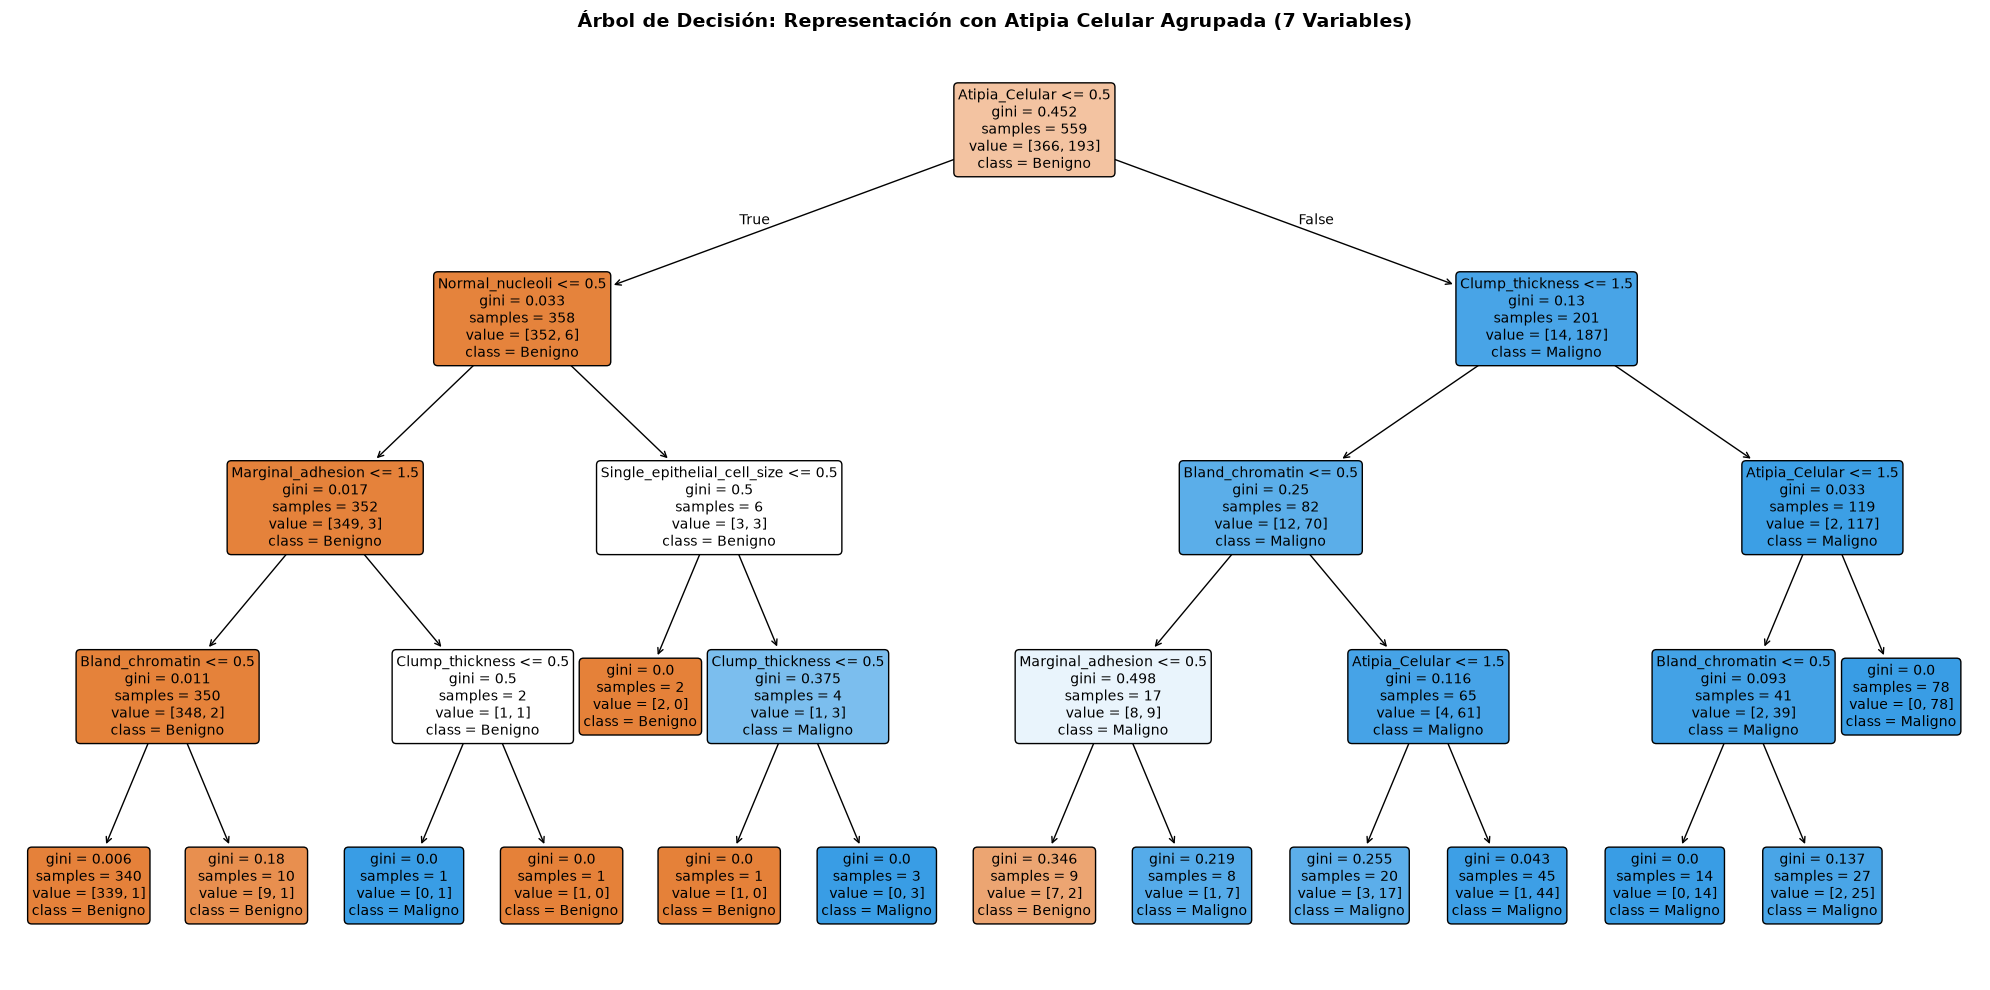

In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

# ==============================================================================
# 1. CARGA Y SEPARACIÓN TRAIN / TEST INDEPENDIENTE
# ==============================================================================
feature_cols = [
    'Clump_thickness',
    'Uniformity_of_cell_size',
    'Uniformity_of_cell_shape',
    'Marginal_adhesion',
    'Single_epithelial_cell_size',
    'Bare_nuclei',
    'Bland_chromatin',
    'Normal_nucleoli',
    'Mitoses',
]

df = pd.read_csv('../data/raw/breast_cancer_original.csv')
if 'Sample_code_number' in df.columns:
  df = df.drop(columns=['Sample_code_number'])

# '?' -> NaN solo convierte el tipo; la imputación se hace dentro del pipeline
X = df[feature_cols].apply(pd.to_numeric, errors='coerce')
# Variable objetivo binaria: 2 (Benigno) -> 0, 4 (Maligno) -> 1
y = df['Class'].map({2: 0, 4: 1}).values

# El test (20%) no se toca hasta la evaluación final
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f'Train: {X_train.shape[0]} | Test: {X_test.shape[0]}')

# ==============================================================================
# 2. TRANSFORMACIONES (todo se ajusta solo con los datos de entrenamiento)
# ==============================================================================
IDX = {c: i for i, c in enumerate(feature_cols)}


def _bin(a):
  # Equivale a pd.cut con cortes en 3 y 6 -> categorías 0, 1, 2
  return (a > 3).astype(int) + (a > 6).astype(int)


def binning_rep2(a):
  return _bin(a)


cols_rep3 = [
    'Clump_thickness',
    'Marginal_adhesion',
    'Single_epithelial_cell_size',
    'Bland_chromatin',
    'Normal_nucleoli',
    'Mitoses',
]
features_rep3 = cols_rep3 + ['Atipia_Celular']


def binning_rep3(a):
  atipia = a[:, [
      IDX['Uniformity_of_cell_size'],
      IDX['Uniformity_of_cell_shape'],
      IDX['Bare_nuclei'],
  ]].mean(axis=1, keepdims=True)
  resto = a[:, [IDX[c] for c in cols_rep3]]
  return _bin(np.hstack([resto, atipia]))


def make_pipeline(transformer):
  # La mediana de Bare_nuclei se aprende solo del train de cada pliegue
  return Pipeline([
      ('imputer', SimpleImputer(strategy='median')),
      ('repr', transformer),
      ('tree', DecisionTreeClassifier(max_depth=4, random_state=42)),
  ])


pipelines = {
    'Rep. 1: Z-Score (9 vars)': make_pipeline(StandardScaler()),
    'Rep. 2: Binning (9 vars)': make_pipeline(FunctionTransformer(binning_rep2)),
    'Rep. 3: Binning Agrupado (7 vars)': make_pipeline(
        FunctionTransformer(binning_rep3)
    ),
}

# ==============================================================================
# 3. VALIDACIÓN CRUZADA (solo sobre train) Y EVALUACIÓN EN TEST
# ==============================================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1']

filas_cv, filas_test = {}, {}
for nombre, pipe in pipelines.items():
  res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas)
  filas_cv[nombre] = {
      'Accuracy': f"{res['test_accuracy'].mean():.4f} ± {res['test_accuracy'].std():.4f}",
      'Precision': f"{res['test_precision'].mean():.4f}",
      'Recall': f"{res['test_recall'].mean():.4f}",
      'F1': f"{res['test_f1'].mean():.4f}",
  }
  pipe.fit(X_train, y_train)
  pred = pipe.predict(X_test)
  filas_test[nombre] = {
      'Accuracy': f'{accuracy_score(y_test, pred):.4f}',
      'Precision': f'{precision_score(y_test, pred):.4f}',
      'Recall': f'{recall_score(y_test, pred):.4f}',
      'F1': f'{f1_score(y_test, pred):.4f}',
  }

print('\n--- 5-Fold CV sobre TRAIN ---')
print(pd.DataFrame(filas_cv).to_string())
print('\n--- TEST INDEPENDIENTE (modelo entrenado con todo el train) ---')
print(pd.DataFrame(filas_test).to_string())

# ==============================================================================
# 4. GRAFICAR Y EXPORTAR EL ÁRBOL DE LA REPRESENTACIÓN 3 (entrenado con train)
# ==============================================================================
dt_rep3 = pipelines['Rep. 3: Binning Agrupado (7 vars)'].named_steps['tree']

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    dt_rep3,
    feature_names=features_rep3,
    class_names=['Benigno', 'Maligno'],
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax,
)
plt.title(
    'Árbol de Decisión: Representación con Atipia Celular Agrupada (7 Variables)',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout()

carpeta_figuras = os.path.join('..', 'reports', 'figures')
os.makedirs(carpeta_figuras, exist_ok=True)
ruta_imagen = os.path.join(carpeta_figuras, 'arbol_decision_atipia_agrupada.png')
plt.savefig(ruta_imagen, dpi=300, bbox_inches='tight')
print(f'\n✓ Imagen del árbol guardada en: {ruta_imagen}')
plt.show()
plt.close()


                             Importancia Gini (train)  Importancia permutación (test, ΔF1)
Atipia_Celular                                 0.9235                               0.0439
Bland_chromatin                                0.0205                               0.0258
Marginal_adhesion                              0.0196                               0.0729
Clump_thickness                                0.0177                               0.0084
Normal_nucleoli                                0.0122                              -0.0026
Single_epithelial_cell_size                    0.0064                              -0.0034
Mitoses                                        0.0000                               0.0000


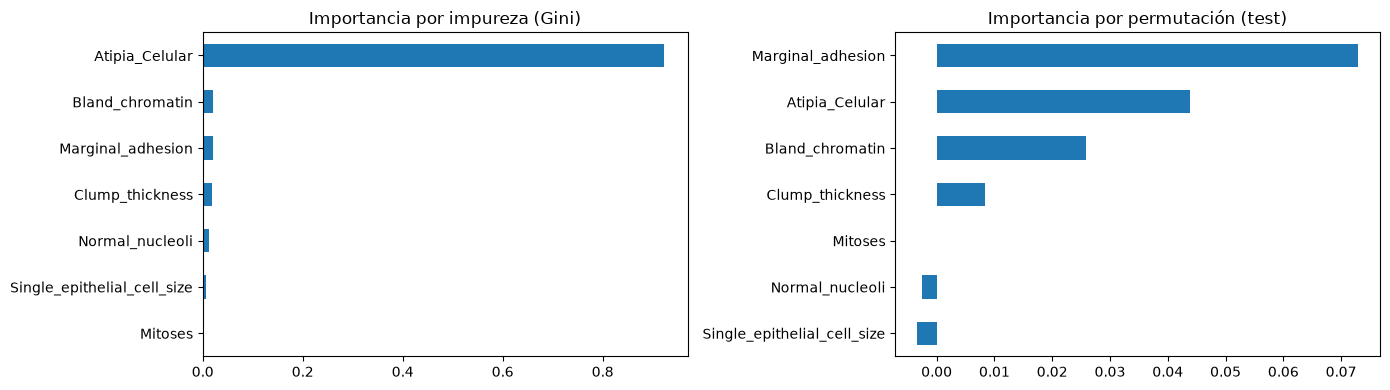

In [3]:
from sklearn.inspection import permutation_importance

pipe_rep3 = pipelines['Rep. 3: Binning Agrupado (7 vars)']

# 1) Importancia por impureza (Gini): cuánto reduce cada variable la impureza
#    en los nodos del árbol. Se calcula solo con train y puede sesgarse.
imp_gini = pd.Series(
    pipe_rep3.named_steps['tree'].feature_importances_, index=features_rep3
)

# 2) Importancia por permutación en TEST: caída del F1 al barajar cada variable.
#    Mide el aporte real a la predicción sobre datos no vistos.
perm = permutation_importance(
    pipe_rep3, X_test, y_test, scoring='f1', n_repeats=30, random_state=42
)
# El pipeline recibe las 9 columnas originales; se agrupan por variable de Rep. 3
orig_cols = list(X_test.columns)
perm_orig = pd.Series(perm.importances_mean, index=orig_cols)
atipia_cols = [
    'Uniformity_of_cell_size', 'Uniformity_of_cell_shape', 'Bare_nuclei'
]
imp_perm = pd.concat([
    perm_orig[cols_rep3],
    pd.Series({'Atipia_Celular': perm_orig[atipia_cols].sum()}),
])

df_imp = pd.DataFrame({
    'Importancia Gini (train)': imp_gini,
    'Importancia permutación (test, ΔF1)': imp_perm,
}).sort_values('Importancia Gini (train)', ascending=False)
print(df_imp.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_imp['Importancia Gini (train)'].sort_values().plot.barh(ax=axes[0])
axes[0].set_title('Importancia por impureza (Gini)')
df_imp['Importancia permutación (test, ΔF1)'].sort_values().plot.barh(
    ax=axes[1]
)
axes[1].set_title('Importancia por permutación (test)')
plt.tight_layout()
plt.savefig(
    os.path.join(carpeta_figuras, 'importancia_features_rep3.png'),
    dpi=300, bbox_inches='tight',
)
plt.show()


## 1. Importancia Gini (por impureza)

**Idea simple:** un árbol hace preguntas del tipo "¿Atipia_Celular ≤ 1?" para separar benignos de malignos. Esta importancia mide cuánto ayuda cada variable a que los grupos queden más "limpios", es decir, con una sola clase.

**Cómo se calcula:**
1. Cada nodo tiene una **impureza Gini**: `1 − (p_benigno² + p_maligno²)`. Vale 0 si el nodo es puro (todos de una clase) y 0.5 si está mezclado 50/50.
2. Cada vez que el árbol divide un nodo con una variable, calcula cuánto bajó la impureza. Esa reducción se multiplica por la fracción de muestras que pasaron por ese nodo.
3. Se suman todas las reducciones de cada variable, en todos los nodos donde se usó.
4. Se normaliza para que todas sumen 1.

**Qué nos dice:** qué variables usó el árbol y cuánto le sirvieron **durante el entrenamiento**. En nuestro caso, `Atipia_Celular = 0.92` significa que ella sola produjo el 92% de toda la limpieza lograda.

**Limitaciones:**
- Se calcula con los datos de train, así que no dice si la variable sirve con datos nuevos.
- Si dos variables son parecidas, el árbol elige una y la otra queda con poca importancia.
- Favorece variables con muchos valores distintos.

## 2. Importancia por permutación (en test)

**Idea simple:** ¿qué pasa si dañamos una variable? Se baraja al azar la columna de esa variable en el test, de modo que pierda su relación con la respuesta. Si el modelo empeora mucho, esa variable era importante.

**Cómo se calcula:**
1. Se mide el F1 del modelo en el test sin modificar (la línea base).
2. Se baraja una columna y se vuelve a medir el F1.
3. Importancia = F1 original − F1 con la columna barajada.
4. Se repite 30 veces (`n_repeats=30`) y se promedia, porque cada barajado da un resultado distinto.

**Qué nos dice:** cuánto depende el modelo de esa variable al predecir **datos que no vio**. Se interpreta así:
- **0.07** (`Marginal_adhesion`): el F1 cae unos 7 puntos al barajarla. Es una variable valiosa.
- **≈ 0** (`Mitoses`): el modelo no la usa o no le aporta.
- **Negativo** (`Normal_nucleoli`): barajarla no empeora nada, incluso mejora un poco por azar. Es ruido.